<a href="https://colab.research.google.com/github/v52wwwn4r9-hash/Assessment-2-AI-Systems/blob/main/AISE_Assessment_2_current.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import io
import pandas as pd

# Upload the CSV file
uploaded = files.upload()

# Read the uploaded file into a pandas DataFrame
for filename in uploaded.keys():
    print(f'Successfully loaded: {filename}')
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    display(df.head())

Saving synthetic_clinical_dataset (2).csv to synthetic_clinical_dataset (2).csv
Successfully loaded: synthetic_clinical_dataset (2).csv


,patient_id,age,sex,bmi,systolic_bp,diastolic_bp,glucose,cholesterol,creatinine,diabetes,hypertension,diagnosis,readmission_30d,mortality
0,1001,63,Male,24.1,131.0,81.0,136.2,210.3,1.04,0,0,Sepsis,0,0
1,1002,52,Male,20.8,118.0,91.0,136.5,207.9,1.49,0,1,Normal,0,0
2,1003,66,Male,30.0,144.0,73.0,100.0,179.5,1.15,0,0,Normal,0,0
3,1004,82,Male,16.8,112.0,76.0,117.3,228.3,0.59,0,0,Heart Failure,0,0
4,1005,50,Female,25.4,102.0,65.0,128.0,150.7,1.38,0,0,Normal,0,0


Task 2

In [ ]:
import pandas as pd

# 1. Check dataset summary and missing values
print("--- Missing Values Before Cleaning ---")
print(df.isnull().sum())

# 2. Check for duplicate records based on patient_id
duplicates = df.duplicated(subset=['patient_id']).sum()
print(f"\nNumber of duplicate patient profiles: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates(subset=['patient_id'])
    print("Duplicates removed.")

# 3. Clean numeric columns (impute missing values with median if any)
numeric_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'cholesterol', 'creatinine']
for col in numeric_cols:
    if col in df.columns:
        if df[col].isnull().sum() > 0:
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)
            print(f"Imputed missing values in '{col}' with median: {median_val}")

# 4. Clean categorical columns (impute missing with mode if any)
categorical_cols = ['sex', 'diagnosis']
for col in categorical_cols:
    if col in df.columns:
        if df[col].isnull().sum() > 0:
            mode_val = df[col].mode()[0]
            df[col] = df[col].fillna(mode_val)
            print(f"Imputed missing values in '{col}' with mode: {mode_val}")

# 5. Convert relevant columns to categorical/boolean types
for col in ['diabetes', 'hypertension', 'readmission_30d', 'mortality']:
    if col in df.columns:
        df[col] = df[col].astype(int)

if 'sex' in df.columns:
    df['sex'] = df['sex'].astype('category')

if 'diagnosis' in df.columns:
    df['diagnosis'] = df['diagnosis'].astype('category')

# Display cleaned dataset summary
print("\n--- Cleaned Dataset Info ---")
df.info()
display(df.head())

--- Missing Values Before Cleaning ---
patient_id         0
age                0
sex                0
bmi                0
systolic_bp        0
diastolic_bp       0
glucose            0
cholesterol        0
creatinine         0
diabetes           0
hypertension       0
diagnosis          0
readmission_30d    0
mortality          0
dtype: int64

Number of duplicate patient profiles: 0

--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   patient_id       10000 non-null  int64   
 1   age              10000 non-null  int64   
 2   sex              10000 non-null  category
 3   bmi              10000 non-null  float64 
 4   systolic_bp      10000 non-null  float64 
 5   diastolic_bp     10000 non-null  float64 
 6   glucose          10000 non-null  float64 
 7   cholesterol      10000 non-null  float64 
 8   

,patient_id,age,sex,bmi,systolic_bp,diastolic_bp,glucose,cholesterol,creatinine,diabetes,hypertension,diagnosis,readmission_30d,mortality
0,1001,63,Male,24.1,131.0,81.0,136.2,210.3,1.04,0,0,Sepsis,0,0
1,1002,52,Male,20.8,118.0,91.0,136.5,207.9,1.49,0,1,Normal,0,0
2,1003,66,Male,30.0,144.0,73.0,100.0,179.5,1.15,0,0,Normal,0,0
3,1004,82,Male,16.8,112.0,76.0,117.3,228.3,0.59,0,0,Heart Failure,0,0
4,1005,50,Female,25.4,102.0,65.0,128.0,150.7,1.38,0,0,Normal,0,0


In [ ]:
# Feature 1: Pulse Pressure (Systolic BP - Diastolic BP)
if 'systolic_bp' in df.columns and 'diastolic_bp' in df.columns:
    df['pulse_pressure'] = df['systolic_bp'] - df['diastolic_bp']
    print("Feature 1 created: 'pulse_pressure'")

# Feature 2: BMI Category based on clinical thresholds
if 'bmi' in df.columns:
    # Define bins and labels
    bins = [0, 18.5, 24.9, 29.9, float('inf')]
    labels = ['Underweight', 'Normal', 'Overweight', 'Obese']

    df['bmi_category'] = pd.cut(df['bmi'], bins=bins, labels=labels, right=True)
    df['bmi_category'] = df['bmi_category'].astype('category')
    print("Feature 2 created: 'bmi_category'")

# Display the new features along with relevant columns
display(df[['patient_id', 'systolic_bp', 'diastolic_bp', 'pulse_pressure', 'bmi', 'bmi_category']].head())

Feature 1 created: 'pulse_pressure'
Feature 2 created: 'bmi_category'


,patient_id,systolic_bp,diastolic_bp,pulse_pressure,bmi,bmi_category
0,1001,131.0,81.0,50.0,24.1,Normal
1,1002,118.0,91.0,27.0,20.8,Normal
2,1003,144.0,73.0,71.0,30.0,Obese
3,1004,112.0,76.0,36.0,16.8,Underweight
4,1005,102.0,65.0,37.0,25.4,Overweight


In [ ]:
def preprocess_clinical_data(raw_df):
    """
    A repeatable preprocessing pipeline for clinical datasets.
    Cleans missing data, optimizes data types, and engineers clinical features.
    """
    # Create a copy to avoid SettingWithCopyWarning
    processed_df = raw_df.copy()

    # 1. Remove duplicates based on patient_id
    if 'patient_id' in processed_df.columns:
        processed_df = processed_df.drop_duplicates(subset=['patient_id'])

    # 2. Impute Numeric Columns (using median)
    numeric_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'cholesterol', 'creatinine']
    for col in numeric_cols:
        if col in processed_df.columns:
            median_val = processed_df[col].median()
            processed_df[col] = processed_df[col].fillna(median_val)

    # 3. Impute Categorical Columns (using mode)
    categorical_cols = ['sex', 'diagnosis']
    for col in categorical_cols:
        if col in processed_df.columns:
            if not processed_df[col].mode().empty:
                mode_val = processed_df[col].mode()[0]
                processed_df[col] = processed_df[col].fillna(mode_val)

    # 4. Convert Binary flags to int
    binary_cols = ['diabetes', 'hypertension', 'readmission_30d', 'mortality']
    for col in binary_cols:
        if col in processed_df.columns:
            processed_df[col] = processed_df[col].astype(int)

    # 5. Categorical column conversion
    if 'sex' in processed_df.columns:
        processed_df['sex'] = processed_df['sex'].astype('category')
    if 'diagnosis' in processed_df.columns:
        processed_df['diagnosis'] = processed_df['diagnosis'].astype('category')

    # 6. Feature Engineering: Pulse Pressure
    if 'systolic_bp' in processed_df.columns and 'diastolic_bp' in processed_df.columns:
        processed_df['pulse_pressure'] = processed_df['systolic_bp'] - processed_df['diastolic_bp']

    # 7. Feature Engineering: BMI Category
    if 'bmi' in processed_df.columns:
        bins = [0, 18.5, 24.9, 29.9, float('inf')]
        labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
        processed_df['bmi_category'] = pd.cut(processed_df['bmi'], bins=bins, labels=labels, right=True)
        processed_df['bmi_category'] = processed_df['bmi_category'].astype('category')

    return processed_df

In [ ]:
def preprocess_clinical_data_leakage_free(df_split, imputation_values=None):
    """
    A leakage-free repeatable preprocessing pipeline.
    If imputation_values is provided, it uses those pre-calculated statistics (from the training set).
    If None, it calculates them from the current dataframe (intended for the training set only) and returns them.
    """
    processed_df = df_split.copy()
    returned_imputations = {}

    # 1. Remove duplicates based on patient_id
    if 'patient_id' in processed_df.columns:
        processed_df = processed_df.drop_duplicates(subset=['patient_id'])

    # 2. Impute Numeric Columns (using median)
    numeric_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'cholesterol', 'creatinine']
    for col in numeric_cols:
        if col in processed_df.columns:
            if imputation_values and col in imputation_values:
                fill_val = imputation_values[col]
            else:
                fill_val = processed_df[col].median()
                returned_imputations[col] = fill_val
            processed_df[col] = processed_df[col].fillna(fill_val)

    # 3. Impute Categorical Columns (using mode)
    categorical_cols = ['sex', 'diagnosis']
    for col in categorical_cols:
        if col in processed_df.columns:
            if imputation_values and col in imputation_values:
                fill_val = imputation_values[col]
            else:
                fill_val = processed_df[col].mode()[0] if not processed_df[col].mode().empty else None
                returned_imputations[col] = fill_val
            if fill_val is not None:
                processed_df[col] = processed_df[col].fillna(fill_val)

    # 4. Convert Binary flags to int
    binary_cols = ['diabetes', 'hypertension', 'readmission_30d', 'mortality']
    for col in binary_cols:
        if col in processed_df.columns:
            processed_df[col] = processed_df[col].astype(int)

    # 5. Categorical column conversion
    if 'sex' in processed_df.columns:
        processed_df['sex'] = processed_df['sex'].astype('category')
    if 'diagnosis' in processed_df.columns:
        processed_df['diagnosis'] = processed_df['diagnosis'].astype('category')

    # 6. Feature Engineering: Pulse Pressure
    if 'systolic_bp' in processed_df.columns and 'diastolic_bp' in processed_df.columns:
        processed_df['pulse_pressure'] = processed_df['systolic_bp'] - processed_df['diastolic_bp']

    # 7. Feature Engineering: BMI Category
    if 'bmi' in processed_df.columns:
        bins = [0, 18.5, 24.9, 29.9, float('inf')]
        labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
        processed_df['bmi_category'] = pd.cut(processed_df['bmi'], bins=bins, labels=labels, right=True)
        processed_df['bmi_category'] = processed_df['bmi_category'].astype('category')

    if imputation_values is None:
        return processed_df, returned_imputations
    return processed_df

Task 3

In [ ]:
# 1. Preprocess the loaded DataFrame 'df'
df_pipeline_output = preprocess_clinical_data(df)

# 2. Perform chronological split
# Earliest 70% for training
# Next 15% for validation
# Latest 15% for testing
n_samples = len(df_pipeline_output)
train_end = int(0.70 * n_samples)
val_end = int(0.85 * n_samples)

train_df = df_pipeline_output.iloc[:train_end]
val_df = df_pipeline_output.iloc[train_end:val_end]
test_df = df_pipeline_output.iloc[val_end:]

# Verify proportions and dimensions
print("Chronological Split Proportions:")
print(f"- Training set (earliest 70%): {train_df.shape[0]} samples ({train_df.shape[0] / n_samples * 100:.1f}%)")
print(f"- Validation set (next 15%): {val_df.shape[0]} samples ({val_df.shape[0] / n_samples * 100:.1f}%)")
print(f"- Test set (latest 15%): {test_df.shape[0]} samples ({test_df.shape[0] / n_samples * 100:.1f}%)")

Chronological Split Proportions:
- Training set (earliest 70%): 7000 samples (70.0%)
- Validation set (next 15%): 1500 samples (15.0%)
- Test set (latest 15%): 1500 samples (15.0%)


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define the target and feature columns
target_column = 'readmission_30d'
# Exclude identifiers and categorical variables that require encoding for the baseline
feature_cols = [col for col in train_df.columns if col not in [target_column, 'patient_id', 'bmi_category', 'sex', 'diagnosis']]

X_train = train_df[feature_cols]
y_train = train_df[target_column]

X_val = val_df[feature_cols]
y_val = val_df[target_column]

# Initialize and train the Dummy Classifier (predicting the most frequent class)
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

# Make predictions on the validation set
y_pred_val = dummy_clf.predict(X_val)
accuracy = accuracy_score(y_val, y_pred_val)

print("Baseline Dummy Classifier Performance (Most Frequent Strategy):")
print(f"Validation Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred_val, zero_division=0))

Baseline Dummy Classifier Performance (Most Frequent Strategy):
Validation Accuracy: 0.8667

Classification Report:
              precision    recall  f1-score   support

           0       0.87      1.00      0.93      1300
           1       0.00      0.00      0.00       200

    accuracy                           0.87      1500
   macro avg       0.43      0.50      0.46      1500
weighted avg       0.75      0.87      0.80      1500



In [ ]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Define feature groups (consistent across all models)
numeric_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'cholesterol', 'creatinine', 'pulse_pressure']
categorical_cols = ['sex', 'diagnosis', 'bmi_category']
binary_cols = ['diabetes', 'hypertension', 'mortality']

all_features = numeric_cols + categorical_cols + binary_cols
target_column = 'readmission_30d'

# Re-align feature and target sets for both training and validation split
X_train_full = train_df[all_features]
y_train_full = train_df[target_column]

X_val_full = val_df[all_features]
y_val_full = val_df[target_column]

# 2. Build the unified column preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ],
    remainder='passthrough' # Keep binary columns unchanged
)

# 3. Create consistent pipelines for all models
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100))
])

# 4. Train & Evaluate Baseline Model
baseline_pipeline.fit(X_train_full, y_train_full)
y_pred_base = baseline_pipeline.predict(X_val_full)
print("=== Unified Preprocessed Baseline (Dummy - Most Frequent) ===")
print(f"Validation Accuracy: {accuracy_score(y_val_full, y_pred_base):.4f}")
print(classification_report(y_val_full, y_pred_base, zero_division=0))

# 5. Train & Evaluate Logistic Regression
log_reg_pipeline.fit(X_train_full, y_train_full)
y_pred_lr = log_reg_pipeline.predict(X_val_full)
print("=== Unified Preprocessed Logistic Regression (Balanced) ===")
print(f"Validation Accuracy: {accuracy_score(y_val_full, y_pred_lr):.4f}")
print(classification_report(y_val_full, y_pred_lr))

# 6. Train & Evaluate Random Forest
rf_pipeline.fit(X_train_full, y_train_full)
y_pred_rf = rf_pipeline.predict(X_val_full)
print("=== Unified Preprocessed Random Forest (Balanced) ===")
print(f"Validation Accuracy: {accuracy_score(y_val_full, y_pred_rf):.4f}")
print(classification_report(y_val_full, y_pred_rf))

=== Unified Preprocessed Baseline (Dummy - Most Frequent) ===
Validation Accuracy: 0.8667
              precision    recall  f1-score   support

           0       0.87      1.00      0.93      1300
           1       0.00      0.00      0.00       200

    accuracy                           0.87      1500
   macro avg       0.43      0.50      0.46      1500
weighted avg       0.75      0.87      0.80      1500

=== Unified Preprocessed Logistic Regression (Balanced) ===
Validation Accuracy: 0.6540
              precision    recall  f1-score   support

           0       0.91      0.67      0.77      1300
           1       0.21      0.58      0.31       200

    accuracy                           0.65      1500
   macro avg       0.56      0.62      0.54      1500
weighted avg       0.82      0.65      0.71      1500

=== Unified Preprocessed Random Forest (Balanced) ===
Validation Accuracy: 0.8660
              precision    recall  f1-score   support

           0       0.87      1.

=== Performance Comparison on Validation Set ===
Baseline Dummy  -> ROC-AUC: 0.5000 | PR-AUC (AP): 0.1333
Logistic Reg.   -> ROC-AUC: 0.6319 | PR-AUC (AP): 0.2032
Random Forest   -> ROC-AUC: 0.5742 | PR-AUC (AP): 0.1628


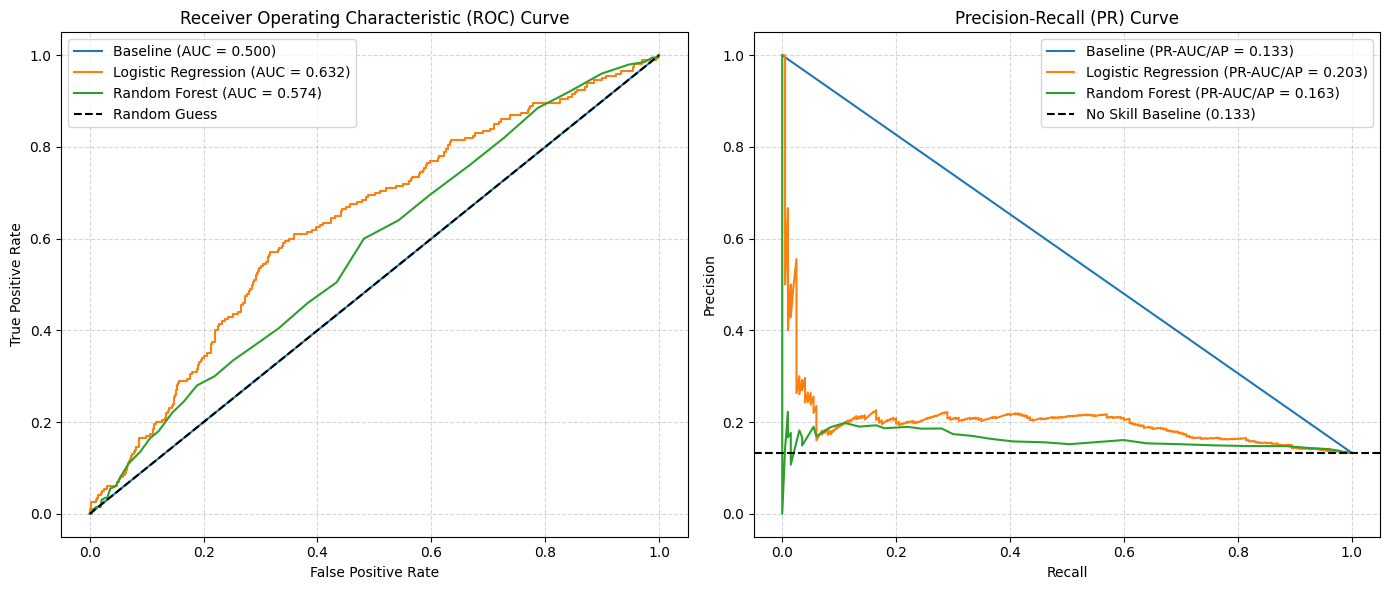

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

# Get probability estimates for the validation set
# (Note: Dummy Classifier using 'most_frequent' does not provide informative probabilities, but we can plot its trivial prediction)
y_prob_base = baseline_pipeline.predict_proba(X_val_full)[:, 1]
y_prob_lr = log_reg_pipeline.predict_proba(X_val_full)[:, 1]
y_prob_rf = rf_pipeline.predict_proba(X_val_full)[:, 1]

# Calculate ROC-AUC Scores
auc_base = roc_auc_score(y_val_full, y_prob_base)
auc_lr = roc_auc_score(y_val_full, y_prob_lr)
auc_rf = roc_auc_score(y_val_full, y_prob_rf)

# Calculate PR-AUC (Average Precision) Scores
ap_base = average_precision_score(y_val_full, y_prob_base)
ap_lr = average_precision_score(y_val_full, y_prob_lr)
ap_rf = average_precision_score(y_val_full, y_prob_rf)

print("=== Performance Comparison on Validation Set ===")
print(f"Baseline Dummy  -> ROC-AUC: {auc_base:.4f} | PR-AUC (AP): {ap_base:.4f}")
print(f"Logistic Reg.   -> ROC-AUC: {auc_lr:.4f} | PR-AUC (AP): {ap_lr:.4f}")
print(f"Random Forest   -> ROC-AUC: {auc_rf:.4f} | PR-AUC (AP): {ap_rf:.4f}")

# Plot ROC and Precision-Recall Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot ROC Curve
for name, probs, auc_score in [
    ('Baseline', y_prob_base, auc_base),
    ('Logistic Regression', y_prob_lr, auc_lr),
    ('Random Forest', y_prob_rf, auc_rf)
]:
    fpr, tpr, _ = roc_curve(y_val_full, probs)
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

ax1.plot([0, 1], [0, 1], 'k--', label='Random Guess')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Precision-Recall Curve
for name, probs, ap_score in [
    ('Baseline', y_prob_base, ap_base),
    ('Logistic Regression', y_prob_lr, ap_lr),
    ('Random Forest', y_prob_rf, ap_rf)
]:
    precision, recall, _ = precision_recall_curve(y_val_full, probs)
    ax2.plot(recall, precision, label=f"{name} (PR-AUC/AP = {ap_score:.3f})")

# Baseline rate of readmission (no-skill baseline on PR curve)
no_skill = y_val_full.sum() / len(y_val_full)
ax2.axhline(y=no_skill, color='k', linestyle='--', label=f'No Skill Baseline ({no_skill:.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall (PR) Curve')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== Tabular Performance Comparison ===


,Metric,Baseline Dummy,Logistic Regression (Candidate)
0,Accuracy,0.8667,0.6540
1,ROC-AUC,0.5000,0.6319
2,PR-AUC (AP),0.1333,0.2032
3,Recall (Class 1),0.0000,0.5800
4,F1-Score (Class 1),0.0000,0.3089


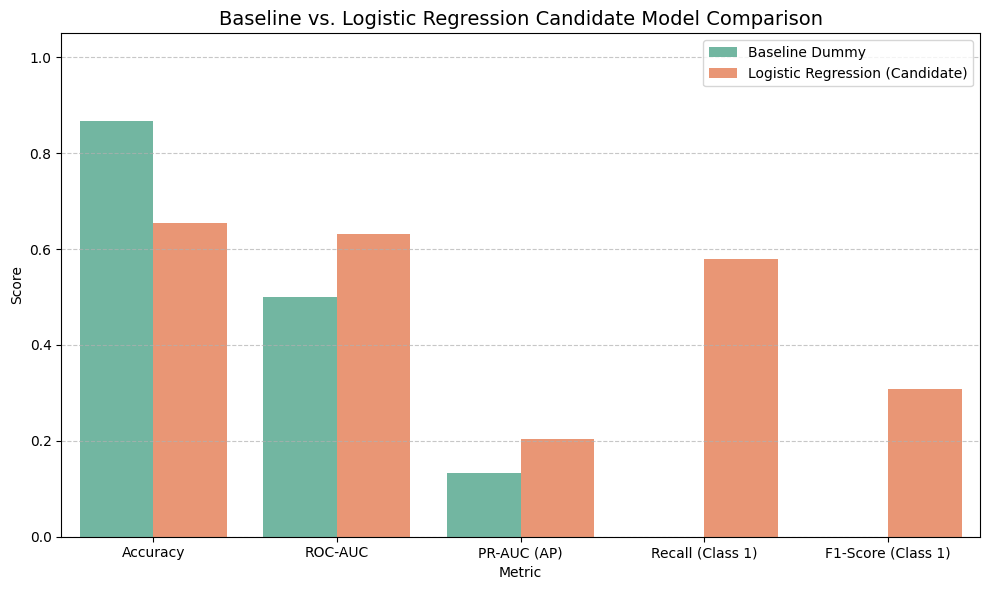

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score, f1_score

# 1. Collect classification statistics
metrics_dict = {
    'Metric': ['Accuracy', 'ROC-AUC', 'PR-AUC (AP)', 'Recall (Class 1)', 'F1-Score (Class 1)'],
    'Baseline Dummy': [
        accuracy_score(y_val_full, y_pred_base),
        auc_base,
        ap_base,
        recall_score(y_val_full, y_pred_base, zero_division=0),
        f1_score(y_val_full, y_pred_base, zero_division=0)
    ],
    'Logistic Regression (Candidate)': [
        accuracy_score(y_val_full, y_pred_lr),
        auc_lr,
        ap_lr,
        recall_score(y_val_full, y_pred_lr),
        f1_score(y_val_full, y_pred_lr)
    ]
}

comparison_df = pd.DataFrame(metrics_dict)
print("=== Tabular Performance Comparison ===")
display(comparison_df.style.format(precision=4))

# 2. Reshape dataframe for visualization
melted_df = comparison_df.melt(id_vars='Metric', var_name='Model', value_name='Score')

# 3. Plot Comparison Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Score', hue='Model', data=melted_df, palette='Set2')
plt.title('Baseline vs. Logistic Regression Candidate Model Comparison', fontsize=14)
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Task 4

In [ ]:
import json
import sys
import sklearn
import pandas as pd
import numpy as np

# 1. Document package requirements for exact environment reproduction
requirements = f"""# Core clinical modeling dependencies\n
python-version=={sys.version.split()[0]}
scikit-learn=={sklearn.__version__}
pandas=={pd.__version__}
numpy=={np.__version__}
matplotlib
seaborn
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements)
print("Saved environment dependencies to: requirements.txt")

# 2. Document dataset parameters, pipeline structural configurations, and model metadata
reproduction_config = {
    "pipeline_info": {
        "raw_data_filename": "synthetic_clinical_dataset (2).csv",
        "total_records": len(df),
        "target_variable": "readmission_30d",
        "features_used": {
            "numeric_features": ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose', 'cholesterol', 'creatinine', 'pulse_pressure'],
            "categorical_features": ['sex', 'diagnosis', 'bmi_category'],
            "binary_features": ['diabetes', 'hypertension', 'mortality']
        }
    },
    "chronological_splits": {
        "train_split_percentage": 70.0,
        "val_split_percentage": 15.0,
        "test_split_percentage": 15.0,
        "train_indices": "0 to 6999",
        "validation_indices": "7000 to 8499",
        "test_indices": "8500 to 9999"
    },
    "model_hyperparameters": {
        "baseline_dummy": {
            "strategy": "most_frequent"
        },
        "candidate_logistic_regression": {
            "class_weight": "balanced",
            "max_iter": 1000,
            "random_state": 42
        },
        "candidate_random_forest": {
            "class_weight": "balanced",
            "n_estimators": 100,
            "random_state": 42
        }
    }
}

with open('reproduction_manifest.json', 'w') as f:
    json.dump(reproduction_config, f, indent=4)
print("Saved structural reproducibility parameters to: reproduction_manifest.json")

# Display the reproduction json configuration
print("\n=== Reproduction Manifest Content ===")
print(json.dumps(reproduction_config, indent=2))

Saved environment dependencies to: requirements.txt
Saved structural reproducibility parameters to: reproduction_manifest.json

=== Reproduction Manifest Content ===
{
  "pipeline_info": {
    "raw_data_filename": "synthetic_clinical_dataset (2).csv",
    "total_records": 10000,
    "target_variable": "readmission_30d",
    "features_used": {
      "numeric_features": [
        "age",
        "bmi",
        "systolic_bp",
        "diastolic_bp",
        "glucose",
        "cholesterol",
        "creatinine",
        "pulse_pressure"
      ],
      "categorical_features": [
        "sex",
        "diagnosis",
        "bmi_category"
      ],
      "binary_features": [
        "diabetes",
        "hypertension",
        "mortality"
      ]
    }
  },
  "chronological_splits": {
    "train_split_percentage": 70.0,
    "val_split_percentage": 15.0,
    "test_split_percentage": 15.0,
    "train_indices": "0 to 6999",
    "validation_indices": "7000 to 8499",
    "test_indices": "8500 to 9999

In [ ]:
import subprocess
import sys

# Install MLflow silently
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow"])

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'mlflow'], returncode=0)

In [ ]:
import mlflow
from sklearn.metrics import recall_score, f1_score, accuracy_score, roc_auc_score, average_precision_score

# Configure local MLflow tracking URI
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Clinical_Readmission_Prediction")

# Define the trusted type explicitly for skops serialization
trusted_types = ["sklearn.compose._column_transformer._RemainderColsList"]

# --- 1. Log Baseline Dummy Run ---
with mlflow.start_run(run_name="Baseline_Dummy_Classifier"):
    # Log parameters
    mlflow.log_params({
        "model_type": "DummyClassifier",
        "strategy": "most_frequent",
        "train_split_size": len(X_train_full),
        "val_split_size": len(X_val_full)
    })

    # Log metrics
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_val_full, y_pred_base),
        "roc_auc": auc_base,
        "pr_auc": ap_base,
        "recall_class_1": recall_score(y_val_full, y_pred_base, zero_division=0),
        "f1_class_1": f1_score(y_val_full, y_pred_base, zero_division=0)
    })

    # Log baseline model pipeline with trusted types specified
    mlflow.sklearn.log_model(
        sk_model=baseline_pipeline,
        artifact_path="model",
        skops_trusted_types=trusted_types
    )
    print("Successfully logged Baseline Run to MLflow with trusted types.")

# --- 2. Log Candidate Logistic Regression Run ---
with mlflow.start_run(run_name="Logistic_Regression_Balanced"):
    # Log parameters
    mlflow.log_params({
        "model_type": "LogisticRegression",
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": 42,
        "train_split_size": len(X_train_full),
        "val_split_size": len(X_val_full)
    })

    # Log metrics
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_val_full, y_pred_lr),
        "roc_auc": auc_lr,
        "pr_auc": ap_lr,
        "recall_class_1": recall_score(y_val_full, y_pred_lr),
        "f1_class_1": f1_score(y_val_full, y_pred_lr)
    })

    # Log candidate model pipeline with trusted types specified
    mlflow.sklearn.log_model(
        sk_model=log_reg_pipeline,
        artifact_path="model",
        skops_trusted_types=trusted_types
    )
    print("Successfully logged Logistic Regression Candidate Run to MLflow with trusted types.")

2026/11/28 06:48:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/28 06:48:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Successfully logged Baseline Run to MLflow with trusted types.
Successfully logged Logistic Regression Candidate Run to MLflow with trusted types.
